# 02 · Playing styles: how do we know two players play alike?

When a club sells a player, it doesn't just need *someone good*. It needs someone who can do **the same job**
in the team. A defensive midfielder who wins the ball with hard tackles and one who reads the game and intercepts
passes are both "defensive midfielders", but they play differently.

In this notebook we:

1. Turn each player's skills into a **style profile**.
2. Try to split midfielders into **style groups** with clustering, and see how well that works.
3. Build a **style similarity** score and check that it really recognizes similar players.

The similarity score from this notebook is the "fit" part of our Replacement Finder (`src/finder.py`).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path("../src").resolve()))   # our own modules live in src/
import plot_style
from plot_style import BLUE, ORANGE, AQUA, INK_2, MUTED, EURO, euro

plot_style.apply()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

from finder import OUTFIELD_SKILLS, load_players, style_similarity

players = load_players()                       # end-of-season snapshot, one row per player per version
season = players[players.fifa_version == 22]   # summer 2022
mid = season[season.role.isin(["DM", "CM", "AM"])].copy()
print(f"{len(mid):,} midfielders in FIFA 22")

6,103 midfielders in FIFA 22


## 1. Style is the *shape* of the skill profile, not its height

Every player has 29 detailed outfield skills (crossing, finishing, interceptions and so on). We could compare
players directly on these numbers, but then a great player and a weak player would always look different,
simply because all of the great player's numbers are higher.

We want to compare **style**, not level. So for each player we subtract his own average skill from every skill.
What remains shows what he is *relatively* good and bad at. Here is an example with two defensive midfielders
of very different levels:

In [2]:
def style_profile(df):
    """Each skill minus the player's own average skill."""
    skills = df[OUTFIELD_SKILLS]
    return skills.sub(skills.mean(axis=1), axis=0)

examples = mid[mid.short_name.isin(["Casemiro", "S. Ricci"])].set_index("short_name")
raw = examples[["overall"] + OUTFIELD_SKILLS[20:29]]
profile = style_profile(examples)[OUTFIELD_SKILLS[20:29]]
display(raw.round(0))
display(profile.round(1))

,overall,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle
short_name,,,,,,,,,,
Casemiro,89.0,91.0,87.0,75.0,80.0,66.0,84.0,85.0,88.0,87.0
S. Ricci,71.0,72.0,72.0,60.0,69.0,52.0,75.0,74.0,73.0,72.0


,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking_awareness,defending_standing_tackle,defending_sliding_tackle
short_name,,,,,,,,,
Casemiro,13.9,9.9,-2.1,2.9,-11.1,6.9,7.9,10.9,9.9
S. Ricci,4.3,4.3,-7.7,1.3,-15.7,7.3,6.3,5.3,4.3


In the first table (raw skills) Casemiro is higher almost everywhere, because he's simply a better player.
In the second table (style profile) both have positive numbers for interceptions, marking and tackling, and
negative numbers for things like penalties. **Their shapes are similar even though their levels are not.**
That's exactly what we want to catch: a cheaper player who does the same job, maybe at a lower level today.

## 2. Can we split midfielders into clear style groups?

A natural idea is **clustering**: let an algorithm group players with similar profiles. We use **K-Means**. It places
*k* group centres and assigns every player to the closest centre, then moves each centre to the middle of its
players, and repeats until nothing changes.

How do we choose *k*, the number of groups? A common measure is the **silhouette score**. For each player, it compares
how close he is to his own group with how close he is to the nearest other group. It ranges from −1 to 1:
near 1 means clear, well-separated groups, near 0 means groups that overlap and blend into each other.

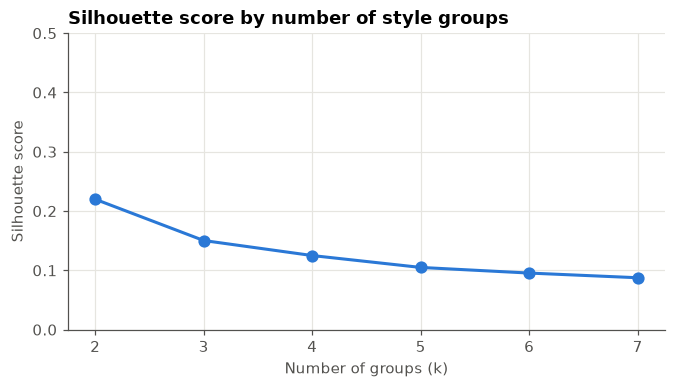

In [3]:
X = style_profile(mid)
scores = {}
for k in range(2, 8):
    labels = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X)
    scores[k] = silhouette_score(X, labels, sample_size=4000, random_state=0)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(list(scores), list(scores.values()), color=BLUE, lw=2, marker="o", ms=7)
ax.set(title="Silhouette score by number of style groups", xlabel="Number of groups (k)",
       ylabel="Silhouette score", ylim=(0, 0.5))
plt.show()

The scores are low: about 0.22 at best, and they fall as we add groups. This is an important (and honest) finding:
**midfield styles are a continuum, not separate boxes.** Most players are a blend, for example "mostly a
defender, a bit of a passer". Any split into groups cuts through crowds of similar players.

Groups are still useful as **labels** for describing players, so we take *k* = 3 (still interpretable) and look at
what makes each group special. For each group we list the skills that are most above and most below the
midfield average.

In [4]:
kmeans = KMeans(n_clusters=3, n_init=10, random_state=0).fit(X)
mid["style_group"] = kmeans.labels_
centres = pd.DataFrame(kmeans.cluster_centers_, columns=OUTFIELD_SKILLS) - X.mean().to_numpy()

for g in range(3):
    print(f"Group {g}: {np.sum(kmeans.labels_ == g):,} players")
    print("   strong:", ", ".join(centres.iloc[g].nlargest(4).index))
    print("   weak:  ", ", ".join(centres.iloc[g].nsmallest(3).index))

Group 0: 2,692 players
   strong: defending_sliding_tackle, defending_standing_tackle, mentality_interceptions, power_jumping
   weak:   skill_curve, skill_fk_accuracy, attacking_volleys
Group 1: 1,787 players
   strong: skill_curve, attacking_finishing, attacking_volleys, skill_fk_accuracy
   weak:   mentality_interceptions, defending_sliding_tackle, defending_standing_tackle
Group 2: 1,624 players
   strong: mentality_interceptions, defending_marking_awareness, defending_standing_tackle, defending_sliding_tackle
   weak:   movement_acceleration, movement_sprint_speed, movement_balance


We give the groups human names with simple rules, so the names stay correct even if the numbering changes:

- the group with the best **curve and finishing** is the **creators** (playmakers who pass, shoot and take free kicks);
- of the other two, the group with more **speed** is the **ball-winners** (they run, tackle and jump);
- the remaining group is the **positional defenders** (they read the game and intercept, but are slower).

In [5]:
creator = centres.skill_curve.idxmax()
others = centres.drop(index=creator)
ball_winner = others.movement_sprint_speed.idxmax()
positional = others.drop(index=ball_winner).index[0]
GROUP_NAMES = {creator: "Creator", ball_winner: "Ball-winner", positional: "Positional defender"}
mid["style_name"] = mid.style_group.map(GROUP_NAMES)

famous = ["Casemiro", "Y. Bissouma", "A. Tchouaméni", "N. Kanté", "C. Eriksen", "K. De Bruyne"]
mid[mid.short_name.isin(famous)][["short_name", "club_name", "main_position", "overall", "style_name"]]

,short_name,club_name,main_position,overall,style_name
154345,C. Eriksen,Brentford,CM,82.0,Creator
154647,K. De Bruyne,Manchester City,CM,91.0,Creator
155379,Casemiro,Real Madrid,CDM,89.0,Positional defender
158212,N. Kanté,Chelsea,CDM,90.0,Ball-winner
163082,Y. Bissouma,Brighton & Hove Albion,CDM,81.0,Positional defender
164760,A. Tchouaméni,Monaco,CM,81.0,Positional defender


These labels match how football people describe these players. Casemiro, Bissouma and Tchouaméni are known as
positional defensive midfielders, Kanté is the classic ball-winner, and Eriksen and De Bruyne are creators.

### Picture: the style map

We can't draw 29 dimensions, so we use **PCA** (Principal Component Analysis) to squeeze the profiles into 2
dimensions while keeping as much of the variation as possible. Each dot is one midfielder, colored by style group.

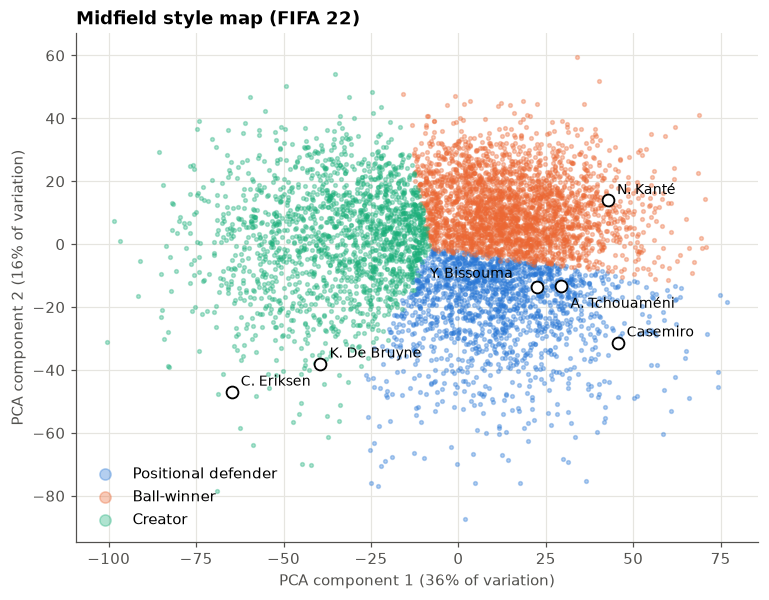

In [6]:
pca = PCA(n_components=2, random_state=0)
xy = pca.fit_transform(X)
mid["pc1"], mid["pc2"] = xy[:, 0], xy[:, 1]

fig, ax = plt.subplots(figsize=(8, 6))
for name, color in zip(["Positional defender", "Ball-winner", "Creator"], [BLUE, ORANGE, AQUA]):
    d = mid[mid.style_name == name]
    ax.scatter(d.pc1, d.pc2, s=6, alpha=0.35, color=color, label=name, rasterized=True)
label_offset = {"A. Tchouaméni": (6, -14), "Y. Bissouma": (-70, 6)}   # keep close labels apart
for _, r in mid[mid.short_name.isin(famous)].iterrows():
    ax.scatter(r.pc1, r.pc2, s=60, color="white", edgecolor="black", lw=1.2, zorder=3)
    ax.annotate(r.short_name, (r.pc1, r.pc2), xytext=label_offset.get(r.short_name, (6, 4)),
                textcoords="offset points", fontsize=9)
ax.set(title="Midfield style map (FIFA 22)",
       xlabel=f"PCA component 1 ({pca.explained_variance_ratio_[0]:.0%} of variation)",
       ylabel=f"PCA component 2 ({pca.explained_variance_ratio_[1]:.0%} of variation)")
ax.legend(markerscale=3, loc="best")
plt.show()

The picture confirms the silhouette score: the three colors touch and blend, and there are no empty gaps between
them. Roughly, the horizontal direction goes from "attacker / creator" (left) to "defender" (right), and the vertical
direction separates the athletic ball-winners (top) from the slower, positional players (bottom).

**Conclusion of this part:** clusters are good for *describing* a player ("he's a positional defender"), but too coarse
for *choosing* a replacement. Two players at opposite corners of one group may still play very differently. We need a
continuous measure instead.

## 3. Style similarity: a continuous measure

For any two players we compute the **cosine similarity** of their style profiles. Imagine each profile as an arrow
in 29-dimensional space. The cosine measures the angle between two arrows:

- 1 means the arrows point in exactly the same direction (identical style),
- 0 means unrelated styles,
- −1 means opposite styles (one's strengths are the other's weaknesses).

Because we already removed each player's average, the length of the arrow (his level) doesn't matter, only the direction.
This is the function `style_similarity` in `src/finder.py`.

Let's find the midfielders whose style is closest to Casemiro's, **at any price**:

In [7]:
casemiro = mid[mid.short_name == "Casemiro"].iloc[0]
others = mid[mid.player_id != casemiro.player_id].copy()
others["similarity"] = style_similarity(others, casemiro)

cols = ["short_name", "age", "club_name", "main_position", "overall", "value_eur", "similarity", "style_name"]
others.nlargest(10, "similarity")[cols].round(3)

,short_name,age,club_name,main_position,overall,value_eur,similarity,style_name
156618,T. Strobl,31.0,FC Augsburg,CDM,74.0,3000000.0,0.936,Positional defender
153697,L. Fejsa,32.0,Al Ahli Jeddah,CDM,75.0,3700000.0,0.901,Positional defender
158877,N. Vukčević,29.0,Levante,CM,74.0,4100000.0,0.894,Positional defender
154902,R. Petrović,32.0,Real Zaragoza,CDM,71.0,1200000.0,0.894,Positional defender
166046,M. Loum,24.0,Deportivo Alavés,CDM,71.0,3500000.0,0.893,Positional defender
158576,R. Battaglia,29.0,Mallorca,CM,75.0,5500000.0,0.881,Positional defender
162074,Garrido,31.0,Mirandés,CDM,72.0,1600000.0,0.879,Positional defender
158226,D. Musto,34.0,Peñarol,CDM,70.0,550000.0,0.877,Positional defender
155044,J. Guilavogui,30.0,Bordeaux,CDM,77.0,9000000.0,0.876,Positional defender
155505,Danilo Pereira,29.0,Paris Saint Germain,CDM,80.0,18000000.0,0.872,Positional defender


The most similar players are all defensive-minded midfielders, at a lower level and much cheaper than Casemiro
(€88M). But look at the ages: most are 29 to 34. Similarity alone happily recommends players at the end of their
careers. That's why the full Finder also needs an age limit and, most of all, a model of **future** level (notebook 03).

### Does the similarity really work? A self-recognition test

How can we check that a similarity measure is meaningful? Here's a simple test. A player's style shouldn't change much
from one season to the next. So if we take a player's FIFA 22 profile and search among **all** FIFA 21 midfielders,
the most similar one should be **the same player** one year earlier.

We run this for 500 random players and record where the real "same player" lands in the ranking.
We compare our measure (cosine on style profiles) with a simpler one: plain Euclidean distance on the raw skills.

In [8]:
prev = players[(players.fifa_version == 21) & players.role.isin(["DM", "CM", "AM"])]
common = np.intersect1d(prev.player_id, mid.player_id)
sample = np.random.default_rng(0).choice(common, 500, replace=False)

prev_ids = prev.player_id.to_numpy()
prev_raw = prev[OUTFIELD_SKILLS].to_numpy(float)
now = mid.set_index("player_id")

rank_cosine, rank_euclid = [], []
for pid in sample:
    target = now.loc[pid]
    sim = style_similarity(prev, target)
    rank_cosine.append(int((sim > sim[prev_ids == pid][0]).sum()) + 1)
    dist = np.linalg.norm(prev_raw - target[OUTFIELD_SKILLS].to_numpy(float), axis=1)
    rank_euclid.append(int((dist < dist[prev_ids == pid][0]).sum()) + 1)

result = pd.DataFrame({
    "found as #1": [np.mean(np.array(r) == 1) for r in (rank_cosine, rank_euclid)],
    "found in top 10": [np.mean(np.array(r) <= 10) for r in (rank_cosine, rank_euclid)],
}, index=["Cosine on style profile (ours)", "Euclidean on raw skills"])
print(f"Searching among {len(prev):,} FIFA 21 midfielders")
result.round(3)

Searching among 6,064 FIFA 21 midfielders


,found as #1,found in top 10
Cosine on style profile (ours),0.864,0.922
Euclidean on raw skills,0.838,0.884


Our measure finds the same player as the **single most similar** of more than 6,000 candidates in about 86% of cases,
and in the top 10 in about 92%. That's better than the plain distance, even though the plain distance has an unfair
advantage: it also uses the player's level, which barely changes in one year.

The cases where it fails are interesting too. Usually the player's ratings changed a lot (young players developing,
or a player retrained to a new position), or there are several near-identical profiles.

## Summary

| Question | Answer |
|---|---|
| How do we describe style? | Skill profile minus the player's own average, so style is separated from level |
| Are there clear style groups? | No, silhouette ≈ 0.22 at best: styles are a continuum |
| Are groups still useful? | Yes, as labels: Creator, Ball-winner, Positional defender (they match football knowledge) |
| What do we use for choosing replacements? | Cosine similarity of style profiles (continuous) |
| Does it work? | Self-recognition test: same player found as #1 in ~86% of cases, top-10 in ~92%, better than raw distance |
| Limitation | FIFA skills are EA's opinion, not match data; the same style on paper may still look different on the pitch |

**Next:** notebook 03 builds the second ingredient, a model that predicts how good a player will be in two years.